In [19]:
import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from sklearn.metrics import mean_squared_error, r2_score


In [20]:
df = pd.read_csv("taxi_trip_pricing.csv")


In [21]:
df = df.dropna(subset=["Trip_Price"]).copy()


In [22]:
numeric_cols = df.select_dtypes(include=["number"]).columns
for col in numeric_cols:
    df[col] = df[col].fillna(df[col].median())

# Fill missing categorical features with their most common value
categorical_cols = df.select_dtypes(include=["object"]).columns

for col in categorical_cols:
    df[col] = df[col].fillna(df[col].mode()[0])



In [23]:
X = df.drop("Trip_Price", axis=1)
y = df["Trip_Price"]


In [24]:
X = pd.get_dummies(X, drop_first=True, dtype=int)


In [25]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

In [26]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)


In [27]:
poly = PolynomialFeatures(degree=3, include_bias=False)

X_train_poly = poly.fit_transform(X_train_scaled)
X_test_poly = poly.transform(X_test_scaled)



In [28]:
poly_scaler = StandardScaler()

X_train_poly = poly_scaler.fit_transform(X_train_poly)
X_test_poly = poly_scaler.transform(X_test_poly)


In [29]:
y_scaler = StandardScaler()

y_train_scaled = y_scaler.fit_transform(
    y_train.to_numpy().reshape(-1, 1)
).ravel()

In [30]:
# Train Polynomial Regression using Mini-Batch Gradient Descent
# Mini-batch GD updates the weights using small groups of training examples.

X_train_mbgd = np.column_stack((np.ones(len(X_train_poly)), X_train_poly))
X_test_mbgd = np.column_stack((np.ones(len(X_test_poly)), X_test_poly))

weights_mbgd = np.zeros(X_train_mbgd.shape[1])

learning_rate = 0.0001
epochs = 100
batch_size = 32

for epoch in range(epochs):
    # Shuffle the training examples at the start of each epoch
    indices = np.random.permutation(len(y_train_scaled))

    # Split the training data into small batches
    for start in range(0, len(indices), batch_size):
        batch = indices[start:start + batch_size]

        X_batch = X_train_mbgd[batch]
        y_batch = y_train_scaled[batch]

        # Predict using the current weights
        predictions = X_batch @ weights_mbgd

        # Calculate the average gradient for this batch
        gradient = X_batch.T @ (predictions - y_batch) / len(batch)

        # Update the weights
        weights_mbgd -= learning_rate * gradient

# Predict trip prices on the test data
mbgd_predictions_scaled = X_test_mbgd @ weights_mbgd

# Convert predictions back to the original trip-price scale
mbgd_predictions = y_scaler.inverse_transform(
    mbgd_predictions_scaled.reshape(-1, 1)
).ravel()

print("Mini-Batch Gradient Descent Results")
print("MSE:", mean_squared_error(y_test, mbgd_predictions))
print("R2 Score:", r2_score(y_test, mbgd_predictions))


Mini-Batch Gradient Descent Results
MSE: 634.3924212560815
R2 Score: 0.728588106331731


In [31]:
# Mini-Batch Gradient Descent uses batches of 32 examples.
# Unlike Adam, it does not use adaptive learning rates or a momentum estimate.


In [32]:
print("Mini-Batch Gradient Descent Results")
print("MSE:", mean_squared_error(y_test, mbgd_predictions))
print("R2 Score:", r2_score(y_test, mbgd_predictions))


Mini-Batch Gradient Descent Results
MSE: 634.3924212560815
R2 Score: 0.728588106331731


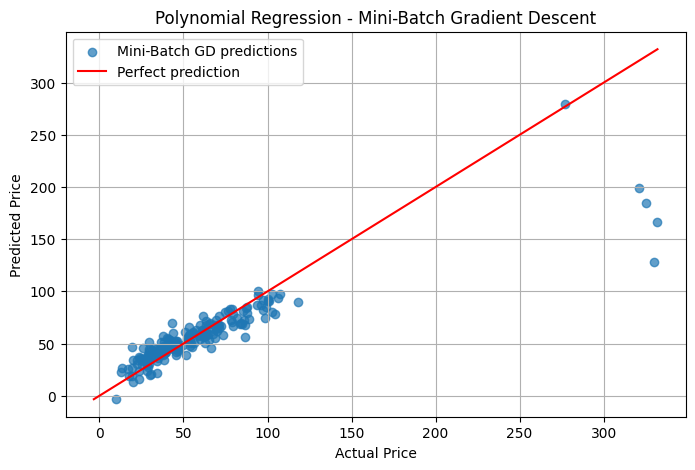

In [33]:
import matplotlib.pyplot as plt

# Actual vs predicted prices for Mini-Batch Gradient Descent
plt.figure(figsize=(8, 5))
plt.scatter(y_test, mbgd_predictions, alpha=0.7, label="Mini-Batch GD predictions")

minimum = min(y_test.min(), mbgd_predictions.min())
maximum = max(y_test.max(), mbgd_predictions.max())
plt.plot([minimum, maximum], [minimum, maximum], color="red",
         label="Perfect prediction")

plt.xlabel("Actual Price")
plt.ylabel("Predicted Price")
plt.title("Polynomial Regression - Mini-Batch Gradient Descent")
plt.legend()
plt.grid(True)
plt.show()


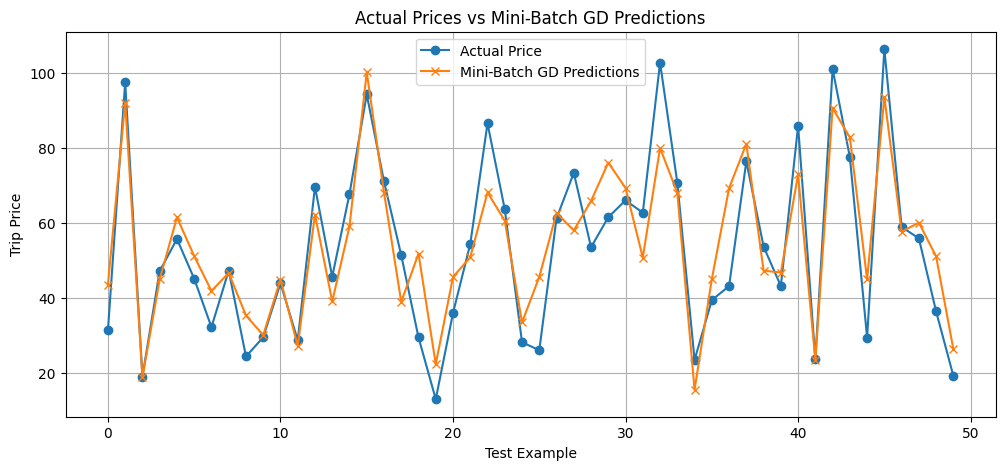

In [34]:
# Show the first 50 test examples
plt.figure(figsize=(12, 5))

plt.plot(np.array(y_test)[:50], marker="o", label="Actual Price")
plt.plot(mbgd_predictions[:50], marker="x", label="Mini-Batch GD Predictions")

plt.xlabel("Test Example")
plt.ylabel("Trip Price")
plt.title("Actual Prices vs Mini-Batch GD Predictions")
plt.legend()
plt.grid(True)
plt.show()


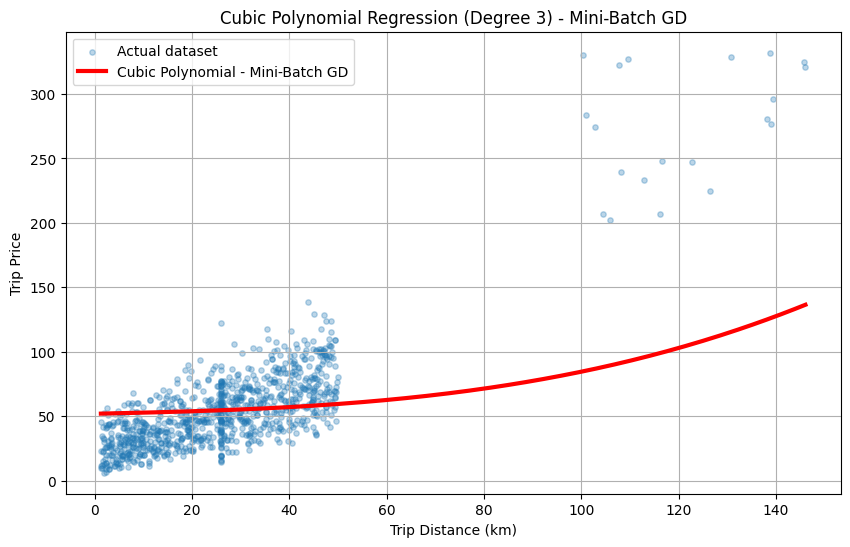

In [35]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Choose one feature for the x-axis
feature = "Trip_Distance_km"

# Create evenly spaced distances for a smooth curve
x_curve = np.linspace(X[feature].min(), X[feature].max(), 200)

# Start with all features at their average values
X_curve = pd.DataFrame([X.mean(numeric_only=True).to_dict()] * len(x_curve))

# Keep the same columns and vary only trip distance
X_curve[feature] = x_curve
X_curve = X_curve[X.columns]

# Apply the same preprocessing used during training
X_curve_scaled = scaler.transform(X_curve)
X_curve_poly = poly.transform(X_curve_scaled)
X_curve_poly = poly_scaler.transform(X_curve_poly)

# Predict with Mini-Batch Gradient Descent
X_curve_mbgd = np.column_stack((np.ones(len(X_curve_poly)), X_curve_poly))
y_mbgd_curve = y_scaler.inverse_transform(
    (X_curve_mbgd @ weights_mbgd).reshape(-1, 1)
).ravel()

# Plot the original dataset and Mini-Batch GD curve
plt.figure(figsize=(10, 6))
plt.scatter(X[feature], y, alpha=0.3, s=15, label="Actual dataset")
plt.plot(x_curve, y_mbgd_curve, color="red", linewidth=3,
         label="Cubic Polynomial - Mini-Batch GD")

plt.xlabel("Trip Distance (km)")
plt.ylabel("Trip Price")
plt.title("Cubic Polynomial Regression (Degree 3) - Mini-Batch GD")
plt.legend()
plt.grid(True)
plt.show()


In [36]:
from sklearn.metrics import mean_squared_error, r2_score

mbgd_mse = mean_squared_error(y_test, mbgd_predictions)
mbgd_r2 = r2_score(y_test, mbgd_predictions)

print("===== MINI-BATCH GD RESULTS =====")
print("MSE:", round(mbgd_mse, 2))
print("R2 Score:", round(mbgd_r2, 4))
print("Batch size:", batch_size)


===== MINI-BATCH GD RESULTS =====
MSE: 634.39
R2 Score: 0.7286
Batch size: 32
